# 03 · Exploratory Data Analysis: BYD in the French new passenger-car market

**Project:** BYD France – Business Intelligence & Market Analytics · **Phase 3 · Notebook 3 of 4**

### Purpose
First evidence-based answers to the business questions, using only the **validated Phase 2 v2 datasets**:

| # | Business question | Section |
|---|---|---|
| Q1 | How is BYD performing in France? | 3, 4 |
| Q3 | How is BYD growing over time? | 4 |
| Q4 | How does BYD compare with competitors? | 5, 7 |
| Q5 | What opportunities exist in the French market? | 2, 6 *(descriptive only)* |

Q2 (model mix) and Q6 (recommendations) need model-level data and the KPI phase. They are **not** answered here.

### Analysis rules (applied throughout)
1. **Comparison universe = `in_market_sum == True`.** This excludes the separate Fiat and Abarth rows (they are inside `Fiat + Abarth`) and every `not_listed` row, so nothing is double-counted.
2. **Complete vs partial years:** 2024 and 2025 are complete (Jan–Dec). **2026 covers January–October only.** Full-year figures are never compared with 2026. Year-on-year comparisons use **January–October of every year**.
3. **Year totals use CCFA's published YTD** (December YTD for full years, October YTD for Jan–Oct), never a re-summed total. Summing the months differs by a few cars because of documented CCFA revisions.
4. **Missing stays missing.** `not_listed` months are NaN. Charts show them as gaps, not zeros.
5. **No conclusion beyond the data.** Registrations ≠ retail sales. Causes (pricing, fleets, incentives) are **not** in this dataset and are not asserted.

Input files are read only. Nothing is written back to `data/processed/`.

## 1 · Load the validated datasets and verify they are the v2 files

**What it does:** uploads the three v2 files (from `data/processed/` on GitHub) and compares each file's **SHA-256 fingerprint** with the fingerprint of the validated v2 export.
**Why:** it proves this analysis uses exactly the files that passed Phase 2 validation, unmodified.
**How to run:** select `brand_month.csv`, `market_month.csv` and `dim_brand.csv` together in the upload dialog.
**What you should see:** three lines ending in `True`.

In [1]:
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

EXPECTED_SHA256 = {   # fingerprints of the validated Phase 2 v2 outputs on GitHub
    "brand_month.csv":  "75c9a78bbe244ce9577894190f5f41fbb38daaf69011726edb2a895e745013ad",
    "market_month.csv": "7f0b6a204092b78e96f1cda41d8766e07545404c09196f4002dc9bea1367b017",
    "dim_brand.csv":    "d34bfc04a27d3038852513c1b00e26dcde4f1e479458ad87e9d386588de4d442",
}
try:
    from google.colab import files
    files.upload()                      # select the three CSV files
except ImportError:
    pass                                # running locally: files are already in the working folder

for name, sha in EXPECTED_SHA256.items():
    actual = hashlib.sha256(open(name, "rb").read()).hexdigest()
    print(f"{name:<18} matches validated v2: {actual == sha}")

bm  = pd.read_csv("brand_month.csv", parse_dates=["date"])
mm  = pd.read_csv("market_month.csv", parse_dates=["date"])
dim = pd.read_csv("dim_brand.csv")

brand_month.csv    matches validated v2: True
market_month.csv   matches validated v2: True
dim_brand.csv      matches validated v2: True


## 1b · Chart style and fixed brand colours

* **Colours follow the brand, never its rank:** BYD is always blue, Tesla orange, MG aqua, Xpeng yellow, Leapmotor magenta. The palette passed a colour-blindness validator. Three colours have low contrast on white, so **lines are labelled directly** and every chart has a table.
* **One y-axis per chart.** Registrations and market share are shown in separate charts, never on a dual axis.

In [2]:
BRAND_COLORS = {"BYD": "#2a78d6", "Tesla": "#eb6834", "MG": "#1baf7a", "Xpeng": "#eda100", "Leapmotor": "#e87ba4"}
YEAR_COLORS  = {2024: "#9ec5f4", 2025: "#5598e7", 2026: "#1c5cab"}       # one blue hue, light -> dark (ordered years)
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e8e7e3"
plt.rcParams.update({
    "figure.figsize": (11, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})
def label_line_ends(ax, series_dict, fmt="{:.1f}%"):
    # direct label at the last non-missing point of each line
    for name, s in series_dict.items():
        s = s.dropna()
        if len(s):
            ax.annotate(f"{name} {fmt.format(s.iloc[-1])}", (s.index[-1], s.iloc[-1]), xytext=(6, 0),
                        textcoords="offset points", va="center", fontsize=9, color=INK)

## 1c · Validation checks before any analysis

| Check | Rule |
|---|---|
| C1 | Shape: 1 734 brand-month rows, 34 months (Jan 2024 – Oct 2026), 51 brands |
| C2 | The comparison universe (`in_market_sum`) adds up exactly to CCFA's market total every month, for the month and YTD |
| C3 | No double counting: `Fiat` / `Abarth` rows are never in the universe |
| C4 | Missing preserved: every `not_listed` row has NaN registrations; no zero was invented |
| C5 | Every brand in the universe has an ownership classification |
| C6 | The five focus brands: months listed (Xpeng is expected to start later) |

In [3]:
U = bm[bm.in_market_sum].merge(dim[["brand", "is_chinese_owned", "is_chinese_origin", "is_joint_venture"]], on="brand", how="left")
checks = {}
checks["C1 rows / months / brands"] = (len(bm), bm.period.nunique(), bm.brand.nunique()) == (1734, 34, 51)
s = U.groupby("period")[["registrations_month", "registrations_ytd"]].sum()
m = mm.set_index("period")
checks["C2 universe = market (month)"] = bool((s.registrations_month == m.market_registrations_month).all())
checks["C2 universe = market (YTD)"]   = bool((s.registrations_ytd == m.market_registrations_ytd).all())
checks["C3 Fiat/Abarth components excluded"] = not U.brand.isin(["Fiat", "Abarth"]).any()
nl = bm[bm.value_type == "not_listed"]
checks["C4 not_listed rows are NaN (no zero-fill)"] = bool(nl[["registrations_month", "registrations_ytd", "share_month_pct"]].isna().all().all())
checks["C5 ownership classified for every brand"] = bool(U.is_chinese_owned.notna().all())
for k, v in checks.items():
    print(f"{k:<45} {v}")

FOCUS = list(BRAND_COLORS)
coverage = (bm[bm.brand.isin(FOCUS)].groupby("brand")
            .agg(months_listed=("listed_in_source", "sum"),
                 first_listed=("period", lambda p: p[bm.loc[p.index, "listed_in_source"]].min()))
            .reindex(FOCUS))
print("\nC6 focus-brand coverage (of 34 months):")
coverage

C1 rows / months / brands                     True
C2 universe = market (month)                  True
C2 universe = market (YTD)                    True
C3 Fiat/Abarth components excluded            True
C4 not_listed rows are NaN (no zero-fill)     True
C5 ownership classified for every brand       True

C6 focus-brand coverage (of 34 months):


,months_listed,first_listed
brand,,
BYD,34,2024-01
Tesla,34,2024-01
MG,34,2024-01
Xpeng,20,2025-03
Leapmotor,34,2024-01


## 2 · The French market: size, trend and seasonality

**Why it matters:** BYD's performance only means something relative to the market it competes in. A growing brand in a shrinking market is gaining share faster than its volume suggests.

In [4]:
full_years = (mm[mm.month == 12].set_index("year")["market_registrations_ytd"].astype(int).rename("published Dec YTD"))
summed     = mm[mm.year.isin([2024, 2025])].groupby("year").market_registrations_month.sum().rename("sum of months")
annual = pd.concat([full_years, summed], axis=1)
annual["difference (CCFA revisions)"] = annual["published Dec YTD"] - annual["sum of months"]
print("Complete years (published December YTD is the reference figure):")
display(annual)

lfl = mm[mm.month == 10].set_index("year")["market_registrations_ytd"].astype(int).rename("Jan–Oct registrations").to_frame()
lfl["change vs previous Jan–Oct"] = (lfl.iloc[:, 0].pct_change() * 100).round(2).map(lambda v: "" if pd.isna(v) else f"{v:+.2f}%")
print("Like-for-like January–October (the only fair comparison including 2026):")
lfl

Complete years (published December YTD is the reference figure):


,published Dec YTD,sum of months,difference (CCFA revisions)
year,,,
2024,1718416,1718421,-5
2025,1632154,1632150,4


Like-for-like January–October (the only fair comparison including 2026):


,Jan–Oct registrations,change vs previous Jan–Oct
year,,
2024,1401435,
2025,1326303,-5.36%
2026,1384293,+4.37%


**Seasonality.** The chart overlays each year's monthly registrations. The index uses the **complete years only** (2024–2025): month ÷ that year's monthly average × 100. Partial 2026 is excluded so its missing November–December can't bias it.

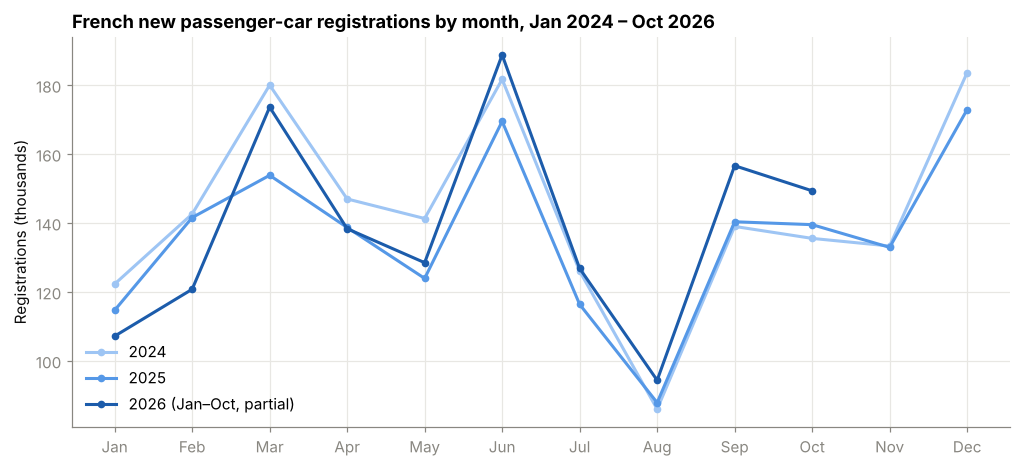

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2024,85.0,100.0,126.0,103.0,99.0,127.0,88.0,60.0,97.0,95.0,93.0,128.0
2025,84.0,104.0,113.0,102.0,91.0,125.0,86.0,65.0,103.0,103.0,98.0,127.0
average index,84.0,102.0,120.0,102.0,95.0,126.0,87.0,62.0,100.0,99.0,96.0,128.0


In [5]:
fig, ax = plt.subplots()
for y, g in mm.groupby("year"):
    lab = f"{y}" + (" (Jan–Oct, partial)" if y == 2026 else "")
    ax.plot(g.month, g.market_registrations_month / 1000, marker="o", ms=4, color=YEAR_COLORS[y], label=lab)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Registrations (thousands)")
ax.set_title("French new passenger-car registrations by month, Jan 2024 – Oct 2026")
ax.legend(loc="lower left")
plt.show()

m2 = mm[mm.year.isin([2024, 2025])].copy()
m2["index"] = m2.market_registrations_month / m2.groupby("year").market_registrations_month.transform("mean") * 100
season = m2.pivot(index="month", columns="year", values="index").round(0)
season["average index"] = season.mean(axis=1).round(0)
season.T

**Reading it:** quarter-end months (March, June, December) sit above the average, and **August is the low point** (index ≈ 62). This matters for every brand-level chart below. A dip in August registrations is a market effect, which is why **market share** is the better month-to-month measure of performance.

## 3 · BYD: monthly registrations (Q1)

All 34 BYD months are `actual` CCFA values. Volume and share are shown in **two separate charts**: different units, one axis each.

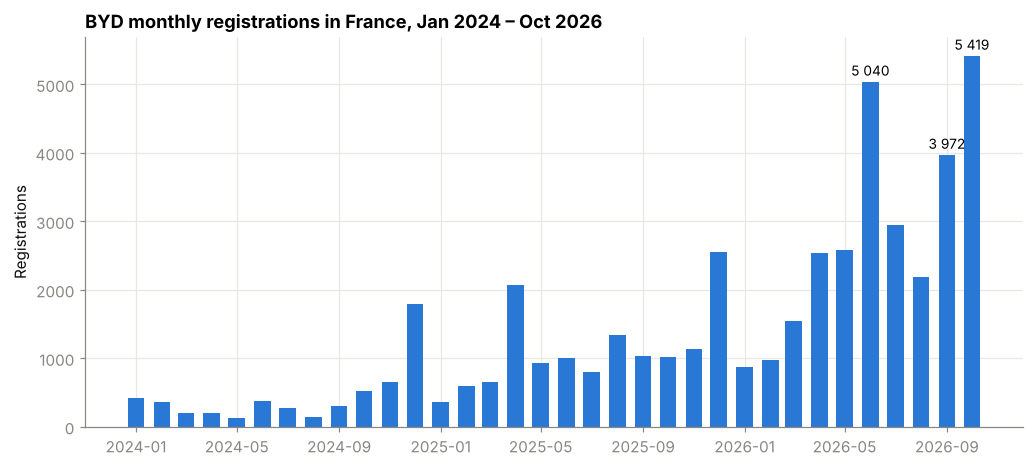

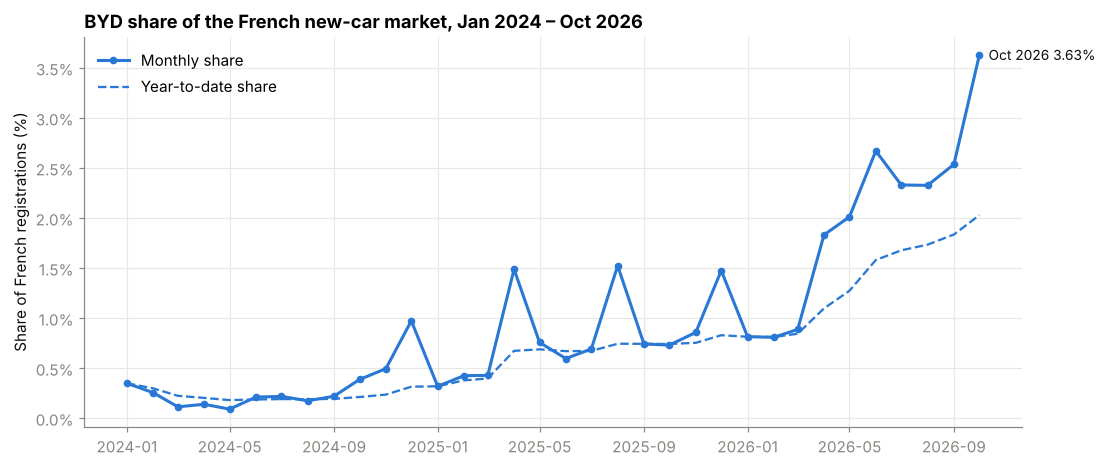

In [6]:
byd = bm[bm.brand == "BYD"].set_index("date").sort_index()
assert (byd.value_type == "actual").all()

fig, ax = plt.subplots()
ax.bar(byd.index, byd.registrations_month, width=20, color=BRAND_COLORS["BYD"])
ax.set_ylabel("Registrations")
ax.set_title("BYD monthly registrations in France, Jan 2024 – Oct 2026")
for d, v in byd.registrations_month.nlargest(3).items():
    ax.annotate(f"{int(v):,}".replace(",", " "), (d, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
plt.show()

fig, ax = plt.subplots()
ax.plot(byd.index, byd.share_month_pct, color=BRAND_COLORS["BYD"], marker="o", ms=4, label="Monthly share")
ax.plot(byd.index, byd.share_ytd_pct, color=BRAND_COLORS["BYD"], ls="--", lw=1.5, label="Year-to-date share")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set_ylabel("Share of French registrations (%)")
ax.set_title("BYD share of the French new-car market, Jan 2024 – Oct 2026")
ax.legend(loc="upper left")
label_line_ends(ax, {"Oct 2026": byd.share_month_pct}, fmt="{:.2f}%")
plt.show()

## 4 · BYD growth: complete years vs partial 2026 (Q3)

In [7]:
def ytd_at(brand, year, month):
    r = bm[(bm.brand == brand) & (bm.year == year) & (bm.month == month)]
    return r.registrations_ytd.iloc[0] if len(r) else np.nan

def mkt_ytd(year, month):
    return mm[(mm.year == year) & (mm.month == month)].market_registrations_ytd.iloc[0]

rows = []
for y in [2024, 2025]:
    rows.append({"period": f"{y} full year (complete)", "BYD registrations": ytd_at("BYD", y, 12),
                 "BYD share %": round(ytd_at("BYD", y, 12) / mkt_ytd(y, 12) * 100, 2)})
for y in [2024, 2025, 2026]:
    rows.append({"period": f"{y} Jan–Oct" + (" (partial year)" if y == 2026 else ""), "BYD registrations": ytd_at("BYD", y, 10),
                 "BYD share %": round(ytd_at("BYD", y, 10) / mkt_ytd(y, 10) * 100, 2)})
growth = pd.DataFrame(rows).set_index("period")
growth["BYD registrations"] = growth["BYD registrations"].astype(int)
display(growth)

print("Growth, complete years: 2025 vs 2024 = "
      f"{(ytd_at('BYD',2025,12)/ytd_at('BYD',2024,12)-1)*100:+.1f}%")
print("Growth, like-for-like Jan–Oct: 2025 vs 2024 = "
      f"{(ytd_at('BYD',2025,10)/ytd_at('BYD',2024,10)-1)*100:+.1f}% | 2026 vs 2025 = "
      f"{(ytd_at('BYD',2026,10)/ytd_at('BYD',2025,10)-1)*100:+.1f}%")
print("Market, like-for-like Jan–Oct: 2026 vs 2025 = "
      f"{(mkt_ytd(2026,10)/mkt_ytd(2025,10)-1)*100:+.2f}%")
print(f"Jan–Oct 2026 already exceeds full-year 2025: {ytd_at('BYD',2026,10) > ytd_at('BYD',2025,12)} "
      "(a partial year vs a complete year: shows scale, not a growth rate)")

,BYD registrations,BYD share %
period,,
2024 full year (complete),5415,0.32
2025 full year (complete),13533,0.83
2024 Jan–Oct,2968,0.21
2025 Jan–Oct,9843,0.74
2026 Jan–Oct (partial year),28086,2.03


Growth, complete years: 2025 vs 2024 = +149.9%
Growth, like-for-like Jan–Oct: 2025 vs 2024 = +231.6% | 2026 vs 2025 = +185.3%
Market, like-for-like Jan–Oct: 2026 vs 2025 = +4.37%
Jan–Oct 2026 already exceeds full-year 2025: True (a partial year vs a complete year: shows scale, not a growth rate)


## 5 · BYD vs competitors (Q4)

**Focus set:** Tesla (the main battery-electric rival), and the Chinese-owned challengers MG, Xpeng and Leapmotor.
**Data availability:** Tesla, MG and Leapmotor are listed all 34 months. **Xpeng is listed only from March 2025**. Earlier months are missing (not zero), so Xpeng has **no 2024 comparison**.

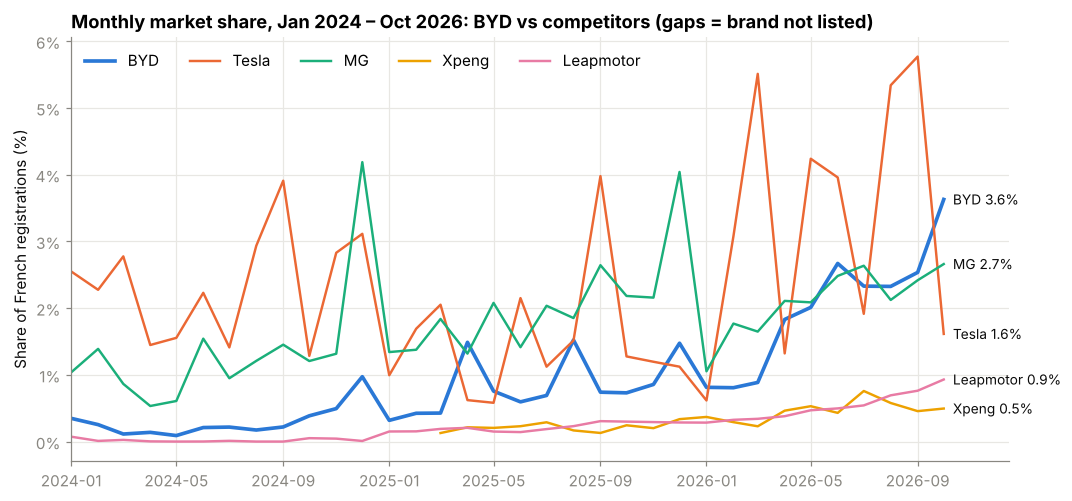

,Jan–Oct 2024,Jan–Oct 2025,Jan–Oct 2026,change 2026 vs 2025,share Jan–Oct 2026 %,full year 2024,full year 2025
BYD,2968.0,9843.0,28086.0,185.3,2.03,5415.0,13533.0
Tesla,31217.0,21927.0,47609.0,117.1,3.44,40709.0,25460.0
MG,15151.0,23872.0,29524.0,23.7,2.13,24599.0,33729.0
Xpeng,NaN,2461.0,6254.0,154.1,0.45,NaN,3313.0
Leapmotor,252.0,2675.0,7292.0,172.6,0.53,330.0,3561.0


In [8]:
share = (bm[bm.brand.isin(FOCUS)].pivot(index="date", columns="brand", values="share_month_pct")[FOCUS])
fig, ax = plt.subplots(figsize=(11, 5))
for b in FOCUS:
    ax.plot(share.index, share[b], color=BRAND_COLORS[b], lw=2.4 if b == "BYD" else 1.6, label=b)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Share of French registrations (%)")
ax.set_title("Monthly market share, Jan 2024 – Oct 2026: BYD vs competitors (gaps = brand not listed)")
ax.legend(loc="upper left", ncol=5)
label_line_ends(ax, {b: share[b] for b in FOCUS})
ax.set_xlim(share.index.min(), share.index.max() + pd.Timedelta(days=75))
plt.show()

comp = pd.DataFrame({b: {f"Jan–Oct {y}": ytd_at(b, y, 10) for y in [2024, 2025, 2026]} for b in FOCUS}).T
comp["change 2026 vs 2025"] = ((comp["Jan–Oct 2026"] / comp["Jan–Oct 2025"] - 1) * 100).round(1)
comp["share Jan–Oct 2026 %"] = (comp["Jan–Oct 2026"] / mkt_ytd(2026, 10) * 100).round(2)
comp["full year 2024"] = [ytd_at(b, 2024, 12) for b in FOCUS]
comp["full year 2025"] = [ytd_at(b, 2025, 12) for b in FOCUS]
comp

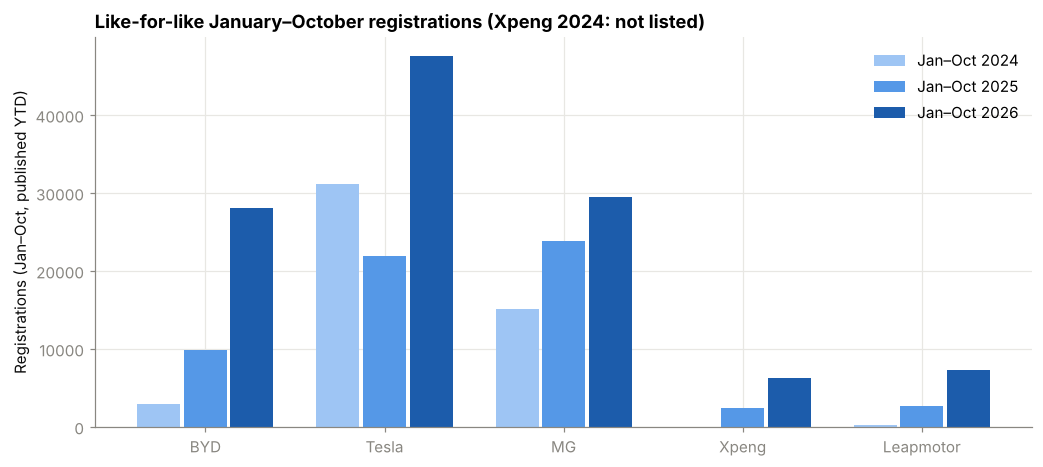

In [9]:
fig, ax = plt.subplots()
x = np.arange(len(FOCUS)); w = 0.26
for i, y in enumerate([2024, 2025, 2026]):
    vals = [ytd_at(b, y, 10) for b in FOCUS]
    ax.bar(x + (i - 1) * w, vals, width=w - 0.02, color=YEAR_COLORS[y], label=f"Jan–Oct {y}")
ax.set_xticks(x, FOCUS)
ax.set_ylabel("Registrations (Jan–Oct, published YTD)")
ax.set_title("Like-for-like January–October registrations (Xpeng 2024: not listed)")
ax.legend()
plt.show()

## 6 · Chinese-owned brands: combined share (Q5)

### Ownership classification methodology (from `dim_brand.csv`)
* **`is_chinese_owned` = True when the brand's controlling owner (majority >50% or sole control) is headquartered in China.**
* Brand heritage is a separate attribute (`is_chinese_origin`). **Volvo** (Swedish brand, majority-owned by Geely) and **MG** (British brand, owned by SAIC) are Chinese-owned but not Chinese-origin.
* **Joint ventures without a controlling owner are excluded**: **Smart** (Mercedes-Benz / Geely 50/50) is `False`.
* **Leapmotor** is `True`: its owner is Chinese; Stellantis holds a minority stake.
* Ownership is general industry knowledge as of November 2026, not CCFA data.

### Measurement caveat: this is a **lower bound**
Only brands **listed separately** by CCFA can be counted. A Chinese-owned brand still inside "AUTRES" is invisible until CCFA lists it (e.g. Chery, Omoda and Zeekr from October 2026). **The true share is between the listed figure and the listed figure + the AUTRES share** (shown as a band). Part of the rise over time comes from **more Chinese brands being listed**, so the number of brands counted is shown alongside.

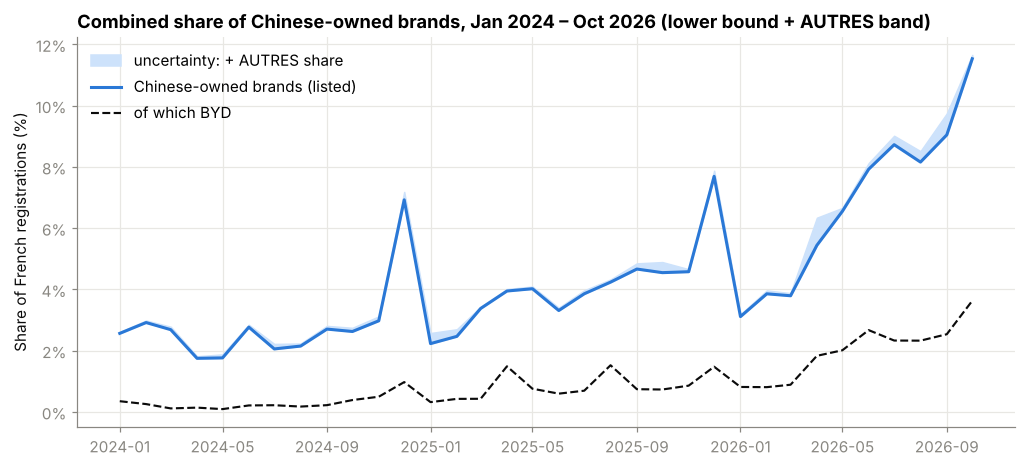

,brands counted,Chinese-owned share %,Chinese-origin only %,BYD % of Chinese-owned volume
period,,,,
2024 full year,5,2.95,0.36,10.7
2025 full year,7,4.20,1.33,19.7
2024 Jan–Oct,5,2.42,0.27,8.7
2025 Jan–Oct,6,3.67,1.18,20.2
2026 Jan–Oct (partial),11,7.07,4.21,28.7


In [10]:
cn = U[U.is_chinese_owned]
cn_month = cn.groupby("date").agg(cn_reg=("registrations_month", "sum"), n_brands=("brand", "nunique"))
cn_month = cn_month.join(mm.set_index("date").market_registrations_month)
cn_month["share_listed_pct"] = cn_month.cn_reg / cn_month.market_registrations_month * 100
autres = bm[bm.brand == "Other brands (AUTRES)"].set_index("date").share_month_pct
cn_month["upper_bound_pct"] = cn_month.share_listed_pct + autres
byd_m = byd.registrations_month
cn_month["byd_share_of_cn_pct"] = byd_m / cn_month.cn_reg * 100

fig, ax = plt.subplots()
ax.fill_between(cn_month.index, cn_month.share_listed_pct, cn_month.upper_bound_pct, color="#cde2fb", label="uncertainty: + AUTRES share")
ax.plot(cn_month.index, cn_month.share_listed_pct, color=BRAND_COLORS["BYD"], label="Chinese-owned brands (listed)")
ax.plot(byd.index, byd.share_month_pct, color=INK, lw=1.4, ls="--", label="of which BYD")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Share of French registrations (%)")
ax.set_title("Combined share of Chinese-owned brands, Jan 2024 – Oct 2026 (lower bound + AUTRES band)")
ax.legend(loc="upper left")
plt.show()

yr = []
for y, mo, lab in [(2024, 12, "2024 full year"), (2025, 12, "2025 full year"), (2024, 10, "2024 Jan–Oct"),
                   (2025, 10, "2025 Jan–Oct"), (2026, 10, "2026 Jan–Oct (partial)")]:
    sub = U[(U.year == y) & (U.month == mo) & U.is_chinese_owned]
    tot = mkt_ytd(y, mo)
    yr.append({"period": lab, "brands counted": sub.brand.nunique(),
               "Chinese-owned share %": round(sub.registrations_ytd.sum() / tot * 100, 2),
               "Chinese-origin only %": round(sub[sub.is_chinese_origin].registrations_ytd.sum() / tot * 100, 2),
               "BYD % of Chinese-owned volume": round(sub[sub.brand == "BYD"].registrations_ytd.sum() / sub.registrations_ytd.sum() * 100, 1)})
pd.DataFrame(yr).set_index("period")

**Note on YTD figures:** for a brand first listed mid-year (e.g. Chery in October 2026), CCFA's published YTD **includes its earlier months**, which were previously inside AUTRES. That makes the YTD-based shares above more complete than the monthly series.

**The reverse case:** a brand listed earlier in the year but **not listed at the period end** has no published YTD for that period, so it is left out (not counted as zero). This affects one Chinese-owned brand: **Skyworth** (74 registrations in Jan–Sep 2026, not listed in October 2026). Its effect on the Jan–Oct 2026 share is about 0.005 percentage points, and the lower bound remains valid.

## 7 · Rankings and competitive positioning (Q4)

**Ranking universe:** all brands in `in_market_sum` **except "AUTRES"**, which is a residual group, not a brand. Ranks are by registrations.

**Missing is never ranked as zero:** a brand not listed in a month (or with no published YTD at the period end) is absent from that ranking, so the number of brands ranked varies (shown as "of n"). For example, Xpeng has no rank before March 2025, and Jaguar and Land Rover are absent from the Jan–Oct 2025 ranking.

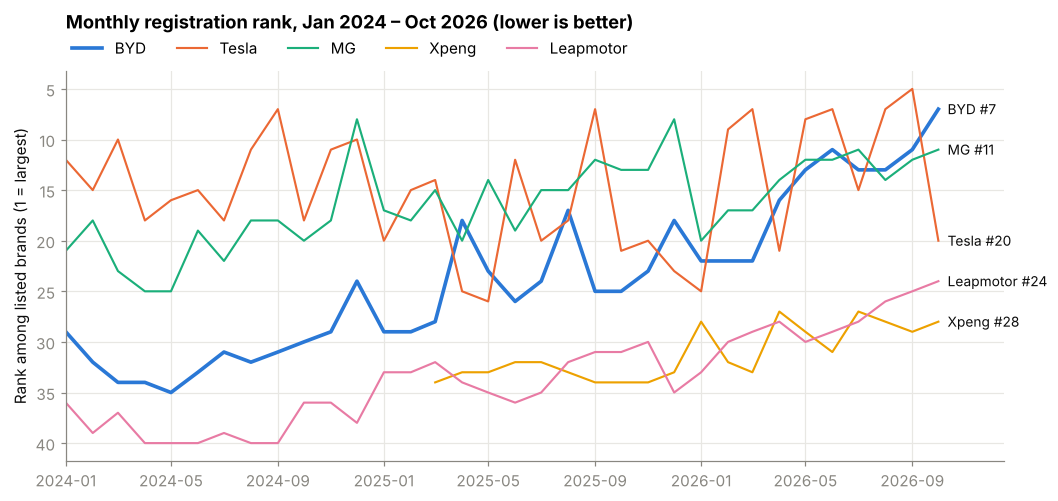

,2024 FY (of 40),2025 FY (of 40),Jan–Oct 2024 (of 40),Jan–Oct 2025 (of 40),Jan–Oct 2026 (of 44)
brand,,,,,
BYD,30.0,24,32.0,24,16
Tesla,14.0,18,15.0,17,7
MG,18.0,14,22.0,15,14
Xpeng,NaN,34,NaN,34,29
Leapmotor,39.0,33,39.0,33,28


In [11]:
R = U[U.brand != "Other brands (AUTRES)"].copy()
R["rank_month"] = R.groupby("period").registrations_month.rank(ascending=False, method="min")
ranks = R[R.brand.isin(FOCUS)].pivot(index="date", columns="brand", values="rank_month")[FOCUS]

fig, ax = plt.subplots()
for b in FOCUS:
    ax.plot(ranks.index, ranks[b], color=BRAND_COLORS[b], lw=2.4 if b == "BYD" else 1.4, label=b)
ax.invert_yaxis()
ax.set_ylabel("Rank among listed brands (1 = largest)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=5, borderaxespad=0)
ax.set_title("Monthly registration rank, Jan 2024 – Oct 2026 (lower is better)", pad=28)
label_line_ends(ax, {b: ranks[b] for b in FOCUS}, fmt="#{:.0f}")
ax.set_xlim(ranks.index.min(), ranks.index.max() + pd.Timedelta(days=75))
plt.show()

def ytd_rank(year, month):
    t = R[(R.year == year) & (R.month == month)].sort_values("registrations_ytd", ascending=False).reset_index(drop=True)
    t["rank"] = t.index + 1
    return t.set_index("brand")["rank"], len(t)
rk = {}
for y, mo, lab in [(2024, 12, "2024 FY"), (2025, 12, "2025 FY"), (2024, 10, "Jan–Oct 2024"), (2025, 10, "Jan–Oct 2025"), (2026, 10, "Jan–Oct 2026")]:
    r, n = ytd_rank(y, mo); rk[f"{lab} (of {n})"] = r.reindex(FOCUS)
pd.DataFrame(rk)

**Competitive positioning:** each dot is a brand with at least 5 000 registrations in January–October 2025 (a meaningful base, so growth rates aren't inflated by tiny volumes). The x-axis is its 2026 share, the y-axis its like-for-like growth. Brands above the dashed line grew faster than the market.

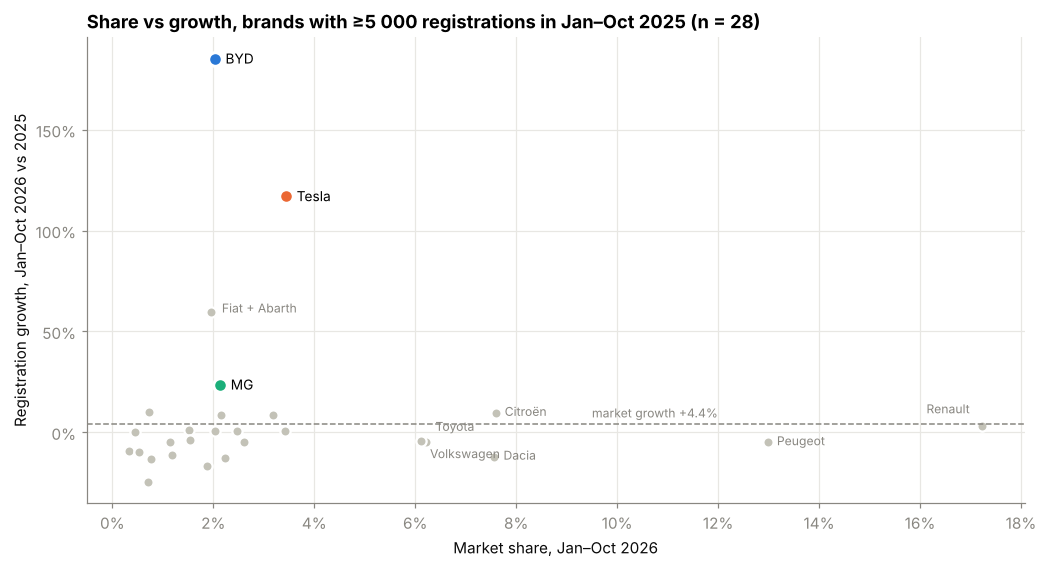

28 brands qualify; 8 grew faster than the market.


year,growth_pct,share_2026_pct
brand,,
BYD,185.34,2.03
Tesla,117.13,3.44
Fiat + Abarth,59.42,1.96
MG,23.68,2.13
Volvo,9.91,0.73
Citroën,9.67,7.59
Skoda,8.68,3.19
Kia,8.58,2.16


In [12]:
o = R[R.month == 10].pivot(index="brand", columns="year", values="registrations_ytd")
o = o[(o[2025] >= 5000) & o[2026].notna()].copy()
o["growth_pct"] = (o[2026] / o[2025] - 1) * 100
o["share_2026_pct"] = o[2026] / mkt_ytd(2026, 10) * 100
mkt_g = (mkt_ytd(2026, 10) / mkt_ytd(2025, 10) - 1) * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
others = o[~o.index.isin(FOCUS)]
ax.scatter(others.share_2026_pct, others.growth_pct, s=45, color="#c3c2b7", edgecolor="white", linewidth=1.5, zorder=2)
for b in [x for x in FOCUS if x in o.index]:
    ax.scatter(o.loc[b, "share_2026_pct"], o.loc[b, "growth_pct"], s=80, color=BRAND_COLORS[b], edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(b, (o.loc[b, "share_2026_pct"], o.loc[b, "growth_pct"]), xytext=(7, 0), textcoords="offset points", va="center", fontsize=9)
offsets = {"Renault": (-8, 8), "Peugeot": (6, -2), "Citroën": (6, -2), "Dacia": (6, -2), "Toyota": (6, 7), "Volkswagen": (6, -11), "Fiat + Abarth": (7, 0)}
for b, off in offsets.items():
    if b in o.index:
        ax.annotate(b, (o.loc[b, "share_2026_pct"], o.loc[b, "growth_pct"]), xytext=off, textcoords="offset points",
                    fontsize=8, color=MUTED, ha="right" if off[0] < 0 else "left")
ax.axhline(mkt_g, color=MUTED, ls="--", lw=1)
ax.annotate(f"market growth {mkt_g:+.1f}%", (9.5, mkt_g), xytext=(0, 4), textcoords="offset points", ha="left", fontsize=8, color=MUTED)
ax.xaxis.set_major_locator(mtick.MultipleLocator(2)); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Market share, Jan–Oct 2026"); ax.set_ylabel("Registration growth, Jan–Oct 2026 vs 2025")
ax.set_title(f"Share vs growth, brands with ≥5 000 registrations in Jan–Oct 2025 (n = {len(o)})")
plt.show()

print(f"{len(o)} brands qualify; {int((o.growth_pct > mkt_g).sum())} grew faster than the market.")
o.sort_values("growth_pct", ascending=False)[["growth_pct", "share_2026_pct"]].round(2).head(8)

## 8 · Final validation of the analysis outputs

Recomputes headline figures independently and checks they match CCFA-published values or earlier phases:
* BYD Jan–Oct 2026 growth equals CCFA's own published YTD change (**+185.3%**).
* BYD full-year totals match the December published YTD (2024: 5 415; 2025: 13 533).
* The Chinese-owned monthly lower bound is ≤ its upper bound in every month, and the gap between them equals the AUTRES share (computed from registrations) in every month.
* Rankings contain no missing values (missing is never ranked as zero).
* No focus-brand month was filled with zero.

In [13]:
v = {}
byd_oct26 = bm[(bm.brand == "BYD") & (bm.period == "2026-10")].iloc[0]
raw_pct = round((ytd_at("BYD", 2026, 10) / ytd_at("BYD", 2025, 10) - 1) * 100, 1)
v["BYD Jan–Oct 2026 growth = 185.3% (CCFA published change)"] = raw_pct == 185.3
v["BYD 2024 FY = 5 415 and 2025 FY = 13 533"] = (ytd_at("BYD", 2024, 12), ytd_at("BYD", 2025, 12)) == (5415, 13533)
v["Chinese-owned lower bound <= upper bound (all months)"] = bool((cn_month.share_listed_pct <= cn_month.upper_bound_pct).all())
au_calc = bm[bm.brand == "Other brands (AUTRES)"].set_index("date").registrations_month / mm.set_index("date").market_registrations_month * 100
v["Upper - lower bound = AUTRES share (all months, ±0.001 pp)"] = bool(((cn_month.upper_bound_pct - cn_month.share_listed_pct - au_calc).abs() < 0.001).all() and cn_month.upper_bound_pct.notna().all())
v["Rankings contain no missing registrations"] = bool(R.registrations_month.notna().all() and R.registrations_ytd.notna().all())
v["No zero-filled focus-brand months"] = bool(bm[bm.brand.isin(FOCUS) & ~bm.listed_in_source].registrations_month.isna().all())
v["Xpeng has no 2024 value (missing, not zero)"] = bool(pd.isna(ytd_at("Xpeng", 2024, 10)))
v["Input files unchanged (SHA-256)"] = all(hashlib.sha256(open(n, "rb").read()).hexdigest() == s for n, s in EXPECTED_SHA256.items())
for k, val in v.items():
    print(f"{k:<62} {val}")

BYD Jan–Oct 2026 growth = 185.3% (CCFA published change)       True
BYD 2024 FY = 5 415 and 2025 FY = 13 533                       True
Chinese-owned lower bound <= upper bound (all months)          True
Upper - lower bound = AUTRES share (all months, ±0.001 pp)     True
Rankings contain no missing registrations                      True
No zero-filled focus-brand months                              True
Xpeng has no 2024 value (missing, not zero)                    True
Input files unchanged (SHA-256)                                True


## 9 · Key findings (descriptive, from the data above)

*Market*
* The French new passenger-car market **fell 5.0% in 2025** (1 632 154 vs 1 718 416 registrations, complete years) and is **up 4.4% in January–October 2026** vs January–October 2025.
* Strong seasonality: **August is the weakest month** (index ≈ 62 of the monthly average); **March, June and December are the peaks**.

*BYD performance and growth (Q1, Q3)*
* Full years: **5 415 (2024) → 13 533 (2025), +149.9%**; share 0.32% → 0.83%.
* Like-for-like Jan–Oct: **2 968 → 9 843 → 28 086**; **+185.3% in 2026 vs 2025**, in a market growing 4.4%. Jan–Oct 2026 share **2.03%**.
* Monthly share reached a series high of **3.63% in October 2026** (5 419 registrations). BYD's monthly rank went from **#29 (Jan 2024) to #7 (Oct 2026)**. Its Jan–Oct rank went from #32 to **#16 of 44**.
* BYD's peak month was **December** in both complete years (2024: 1 787; 2025: 2 551). In 2026 its two largest months are **October (5 419) and June (5 040)**. The data shows when volumes peak, not why.

*Competitors (Q4)*
* Jan–Oct 2026: **Tesla 47 609 (+117.1%)**, **MG 29 524 (+23.7%)**, **BYD 28 086 (+185.3%)**, **Leapmotor 7 292 (+172.6%)**, **Xpeng 6 254 (+154.1%; listed only since March 2025)**.
* BYD is still behind Tesla and MG year-to-date, but **out-registered both in October 2026** (5 419 vs MG 3 974 and Tesla 2 410).
* Among the 28 brands with ≥5 000 registrations in Jan–Oct 2025, **BYD has the highest growth rate**, followed by Tesla.

*Chinese-owned brands (Q5, lower bound)*
* Combined YTD share: **2.95% (2024) → 4.20% (2025)**; **7.07% in Jan–Oct 2026** (11 brands counted, vs 5 in 2024). Chinese-origin brands alone: 4.21%.
* **BYD's part of the Chinese-owned volume rose from 10.7% (2024) to 28.7% (Jan–Oct 2026).**

### Limitations
* **Registrations ≠ retail sales.** They include fleet, rental and demonstration cars; this dataset can't separate them.
* **No powertrain split by brand** (BEV vs PHEV) and **no model detail**, so Q2 isn't answered here.
* The Chinese-owned share is a **lower bound** (brands inside AUTRES can't be counted).
* 2026 is **partial (January–October)**. Full-year 2026 is not estimated.
* All figures are **provisional** CCFA/AAA-DATA publications and subject to revision.

**Next:** notebook 04 / Phase 4–5, KPI definitions and SQL, building on these validated views.